In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("All imports worked")

All imports worked


In [2]:
tickers = ["AAPL", "MSFT", "JNJ", "JPM", "XOM", "PG", "KO", "NVDA", "WMT", "CAT"]

#prices = yf.download(tickers, start="2015-01-01", end="2024-12-31")["Close"]
#prices.to_csv('prices.csv')

prices = pd.read_csv("prices.csv", index_col=0, parse_dates=True)
prices.tail()

,AAPL,CAT,JNJ,JPM,KO,MSFT,NVDA,PG,WMT,XOM
Date,,,,,,,,,,
2024-12-23,253.430847,357.768005,138.723969,230.179581,59.437828,429.338989,139.305832,160.216690,88.927071,100.520279
2024-12-24,256.339722,359.902496,139.277847,233.964584,59.876133,433.363556,139.854416,161.007736,91.220367,100.614822
2024-12-26,257.153809,359.461914,139.020004,234.766006,59.618862,432.160126,139.565155,162.170471,91.328636,100.699936
2024-12-27,253.748550,357.249023,138.513870,232.863846,59.504528,424.683075,136.652756,161.570038,90.216446,100.690475
2024-12-30,250.382950,355.437622,136.880920,231.077591,59.104332,419.060425,137.131516,159.244614,89.143600,100.009621


In [3]:
print(prices.shape)

(2515, 10)


In [4]:
returns = prices.pct_change().dropna()

returns.head()

,AAPL,CAT,JNJ,JPM,KO,MSFT,NVDA,PG,WMT,XOM
Date,,,,,,,,,,
2015-01-05,-0.028171,-0.052786,-0.006984,-0.031045,0.000000,-0.009196,-0.016890,-0.004755,-0.002911,-0.027361
2015-01-06,0.000094,-0.006434,-0.004913,-0.025929,0.007594,-0.014678,-0.030318,-0.004555,0.007706,-0.005316
2015-01-07,0.014022,0.015496,0.022076,0.001526,0.012482,0.012706,-0.002605,0.005246,0.026532,0.010132
2015-01-08,0.038423,0.010249,0.007863,0.022346,0.012096,0.029418,0.037617,0.011436,0.021106,0.016645
2015-01-09,0.001072,-0.011949,-0.013630,-0.017387,-0.011032,-0.008405,0.004028,-0.009331,-0.012380,-0.001410


In [5]:
ann_return = returns.mean() * 252
ann_std = returns.std() * (252 ** 0.5)
ann_var = returns.var() * 252
summary = pd.DataFrame({"Return": ann_return, "Standard_Deviation": ann_std, "Variance": ann_var})

summary

,Return,Standard_Deviation,Variance
AAPL,0.274956,0.284663,0.081033
CAT,0.208913,0.297691,0.088620
JNJ,0.075649,0.180543,0.032596
JPM,0.199055,0.273754,0.074941
KO,0.086546,0.177891,0.031645
MSFT,0.273381,0.271430,0.073674
NVDA,0.683911,0.486098,0.236291
PG,0.106767,0.184745,0.034131
WMT,0.157828,0.211305,0.044650
XOM,0.095348,0.277878,0.077216


In [6]:
ann_cov = returns.cov() * 252
ann_cov

,AAPL,CAT,JNJ,JPM,KO,MSFT,NVDA,PG,WMT,XOM
AAPL,0.081033,0.032447,0.017731,0.032419,0.018629,0.052759,0.074549,0.019375,0.018664,0.023984
CAT,0.032447,0.088620,0.017644,0.049213,0.018751,0.031664,0.049011,0.014267,0.014008,0.046629
JNJ,0.017731,0.017644,0.032596,0.019746,0.016502,0.018835,0.014996,0.017921,0.013878,0.016217
JPM,0.032419,0.049213,0.019746,0.074941,0.022034,0.032796,0.044070,0.017075,0.014484,0.042249
KO,0.018629,0.018751,0.016502,0.022034,0.031645,0.019445,0.016906,0.020509,0.013792,0.019482
MSFT,0.052759,0.031664,0.018835,0.032796,0.019445,0.073674,0.079351,0.021069,0.019370,0.021286
NVDA,0.074549,0.049011,0.014996,0.044070,0.016906,0.079351,0.236291,0.018717,0.021640,0.027245
PG,0.019375,0.014267,0.017921,0.017075,0.020509,0.021069,0.018717,0.034131,0.017561,0.013115
WMT,0.018664,0.014008,0.013878,0.014484,0.013792,0.019370,0.021640,0.017561,0.044650,0.011750
XOM,0.023984,0.046629,0.016217,0.042249,0.019482,0.021286,0.027245,0.013115,0.011750,0.077216


In [7]:
n_assets=len(tickers)
n_assets

10

In [8]:
weights=np.random.random(10)

weights = weights / np.sum(weights)

In [9]:
port_return = np.sum(weights*ann_return)
print(weights)
print(ann_return)
print(port_return)

[0.02147778 0.1281193  0.17431552 0.08564524 0.01348555 0.19913227
 0.01306934 0.10786396 0.10344907 0.15344197]
AAPL    0.274956
CAT     0.208913
JNJ     0.075649
JPM     0.199055
KO      0.086546
MSFT    0.273381
NVDA    0.683911
PG      0.106767
WMT     0.157828
XOM     0.095348
dtype: float64
0.16992432708675875


In [10]:
port_var = (weights.T @ ann_cov @ weights)
print(port_var)

0.02843134671941517


In [11]:
n_portfolios=10000

results = np.zeros((n_portfolios, 3))
all_weights = np.zeros((n_portfolios, n_assets))
for i in range(n_portfolios):
    w=np.random.random(n_assets)
    w = w/np.sum(w)
    all_weights[i, :] = w
    ret=np.sum(w*ann_return)
    vol=np.sqrt(w.T @ ann_cov @ w)
    results[i,0] = ret
    results[i,1] = vol
    results[i,2] = ret/vol

print(results.shape)

(10000, 3)


In [12]:
portfolios = pd.DataFrame(results, columns=['Return','Volatility','Sharpe_Ratio'])
portfolios.head()

,Return,Volatility,Sharpe_Ratio
0,0.194495,0.170497,1.140752
1,0.260930,0.213401,1.222720
2,0.163947,0.162109,1.011337
3,0.201399,0.177057,1.137481
4,0.199132,0.178685,1.114430


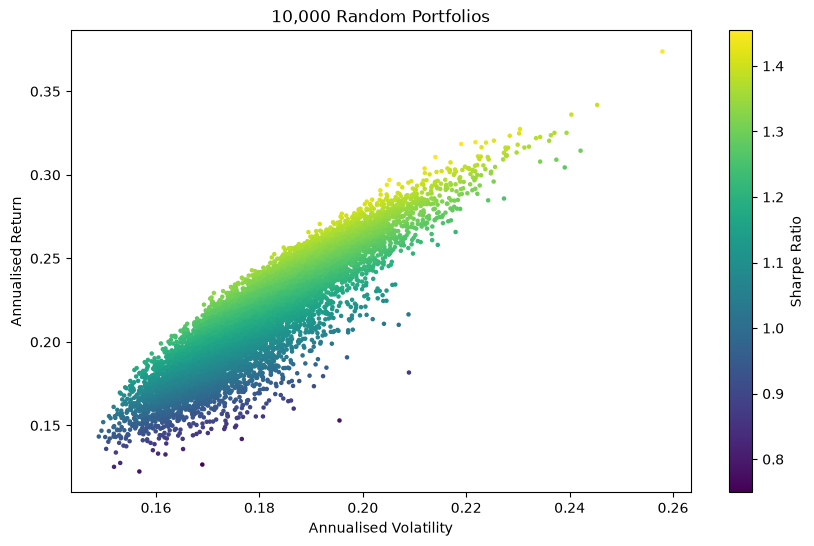

In [13]:
plt.figure(figsize=(10, 6))

plt.scatter(portfolios["Volatility"], portfolios["Return"],
            c=portfolios["Sharpe_Ratio"], cmap="viridis", s=5)

plt.colorbar(label="Sharpe Ratio")
plt.xlabel("Annualised Volatility")
plt.ylabel("Annualised Return")
plt.title("10,000 Random Portfolios")
plt.show()

In [14]:
from scipy.optimize import minimize
#define function to calculate volatility (sd) of a given portfolio
def portfolio_vol(w):
    return np.sqrt(w.T @ ann_cov @ w)

In [23]:
#finding the minimum variance portfolio

constraints = {"type": "eq", "fun": lambda w: np.sum(w) - 1}
bounds = tuple((0, 1) for _ in range(n_assets))
initial = np.repeat(1/n_assets, n_assets)

min_vol = minimize(portfolio_vol, initial, bounds=bounds, constraints=constraints)

print(min_vol.fun)

min_vol_weights = pd.Series(min_vol.x, index=ann_return.index)
print(min_vol_weights.round(4))

0.143739925069746
AAPL    0.0222
CAT     0.0227
JNJ     0.2778
JPM     0.0000
KO      0.2476
MSFT    0.0000
NVDA    0.0012
PG      0.1578
WMT     0.2031
XOM     0.0676
dtype: float64


In [22]:
#define a function to calculate the sharpe ratio for a given portfolio
#calculate the maximum Sharpe ratio and print the portfolio

risk_free = 0.02
def neg_sharpe(w):
    r = np.sum(w * ann_return)
    v = portfolio_vol(w)
    return -(r - risk_free)/v

max_sharpe = minimize(neg_sharpe, initial, bounds=bounds, constraints=constraints)

print(-(max_sharpe.fun))
max_sharpe_weights = pd.Series(max_sharpe.x, index=ann_return.index)
print(max_sharpe_weights.round(4))

1.4254733495309782
AAPL    0.0575
CAT     0.0422
JNJ     0.0000
JPM     0.0763
KO      0.0000
MSFT    0.0000
NVDA    0.5009
PG      0.0000
WMT     0.3232
XOM     0.0000
dtype: float64


In [27]:
max_sharpe_return=np.sum(max_sharpe.x * ann_return)
max_sharpe_vol = portfolio_vol(max_sharpe.x)
min_vol_return = np.sum(min_vol.x * ann_return)
min_vol_vol = portfolio_vol(min_vol.x)

print(max_sharpe_return.round(3), max_sharpe_vol.round(3))
print(min_vol_return.round(3), min_vol_vol.round(3))

0.433 0.29
0.109 0.144


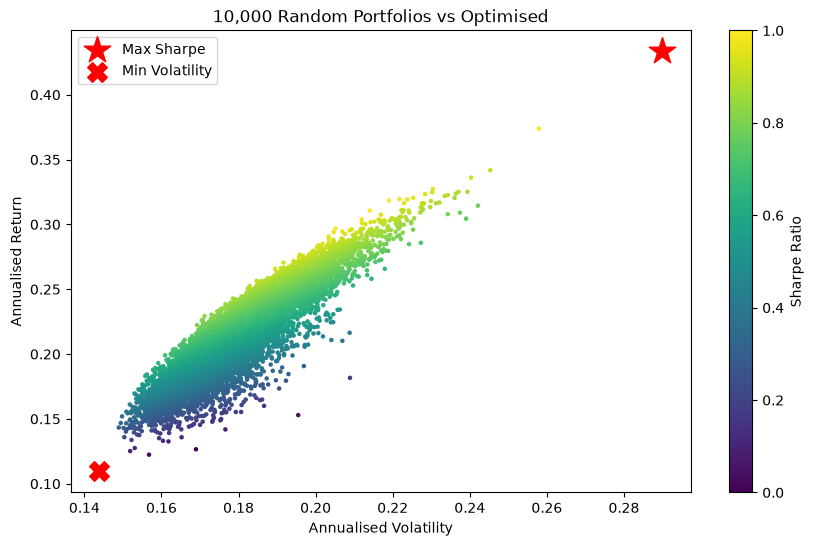

In [29]:
# see where min-variance and max-sharpe portfolios lie in the risk-return space
plt.figure(figsize=(10, 6))

plt.scatter(portfolios["Volatility"], portfolios["Return"],
            c=portfolios["Sharpe_Ratio"], cmap="viridis", s=5)

plt.scatter(max_sharpe_vol, max_sharpe_return, c="red", marker="*", s=400, label="Max Sharpe")
plt.scatter(min_vol_vol, min_vol_return, c="red", marker="X", s=200, label="Min Volatility")

plt.colorbar(label="Sharpe Ratio")
plt.legend()
plt.xlabel("Annualised Volatility")
plt.ylabel("Annualised Return")
plt.title("10,000 Random Portfolios vs Optimised")
plt.show()

In [33]:
#building the effecient frontier
target_returns = np.linspace(min_vol_return, max_sharpe_return, 100)
frontier_vols=[]
for r in target_returns:
    t_constraints = (
        {'type': 'eq', 'fun': lambda w: np.sum(w)-1},
        {'type': 'eq', 'fun': lambda w: np.sum(w * ann_return) - r}
    )
    result = minimize(portfolio_vol, initial, bounds=bounds, constraints=t_constraints)
    frontier_vols.append(result.fun)

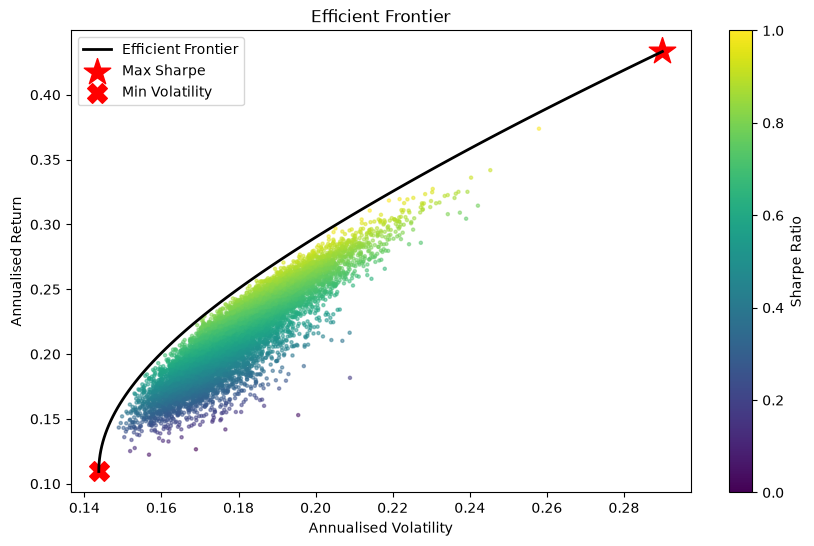

In [36]:
plt.figure(figsize=(10, 6))

plt.scatter(portfolios["Volatility"], portfolios["Return"],
            c=portfolios["Sharpe_Ratio"], cmap="viridis", s=5, alpha=0.5)

plt.plot(frontier_vols, target_returns, color="black", linewidth=2, label="Efficient Frontier")

plt.scatter(max_sharpe_vol, max_sharpe_return, c="red", marker="*", s=400, label="Max Sharpe")
plt.scatter(min_vol_vol, min_vol_return, c="red", marker="X", s=200, label="Min Volatility")

plt.colorbar(label="Sharpe Ratio")
plt.legend()
plt.xlabel("Annualised Volatility")
plt.ylabel("Annualised Return")
plt.title("Efficient Frontier")
plt.show()